# Portafolio de Estadística: Prueba F para Comparación de Dos Varianzas (con Transformación Logarítmica)
Al utilizar datasets con escalas de medición muy diferentes (pesos individuales vs. toneladas de pesca comercial), la varianza original se dispara y el estadístico F pierde proporción visual. Para solucionar esto, aplicaremos una **transformación logarítmica (log10)** a ambas muestras. Esto comprime la escala, permite visualizar distribuciones más simétricas y hace que la comparación de varianzas tenga sentido estadístico y visual.

In [30]:
import pandas as pd
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los datasets enteros
try:
    df_umesc = pd.read_csv('df_limpio.csv')
    m1_orig = df_umesc['weight'].dropna()
    m1_orig = m1_orig[m1_orig > 0] # Evitar log(0)
    
    df_conapesca = pd.read_csv('conapesca_historico_2015_2025_LIMPIO.csv')
    m2_orig = df_conapesca['PESO_VIVO_KG'].dropna()
    m2_orig = m2_orig[m2_orig > 0] # Evitar log(0)
    
except:
    # Dataset simulado de respaldo
    np.random.seed(42)
    m1_orig = pd.Series(np.random.lognormal(mean=6, sigma=1, size=92222))
    m2_orig = pd.Series(np.random.lognormal(mean=10, sigma=1.5, size=117757))

# 1. Transformación Logarítmica (Base 10)
muestra1 = np.log10(m1_orig)
muestra2 = np.log10(m2_orig)

print("Transformación Logarítmica completada con éxito.")

Transformación Logarítmica completada con éxito.


### 2. Análisis Visual: Histogramas de las Distribuciones Logarítmicas

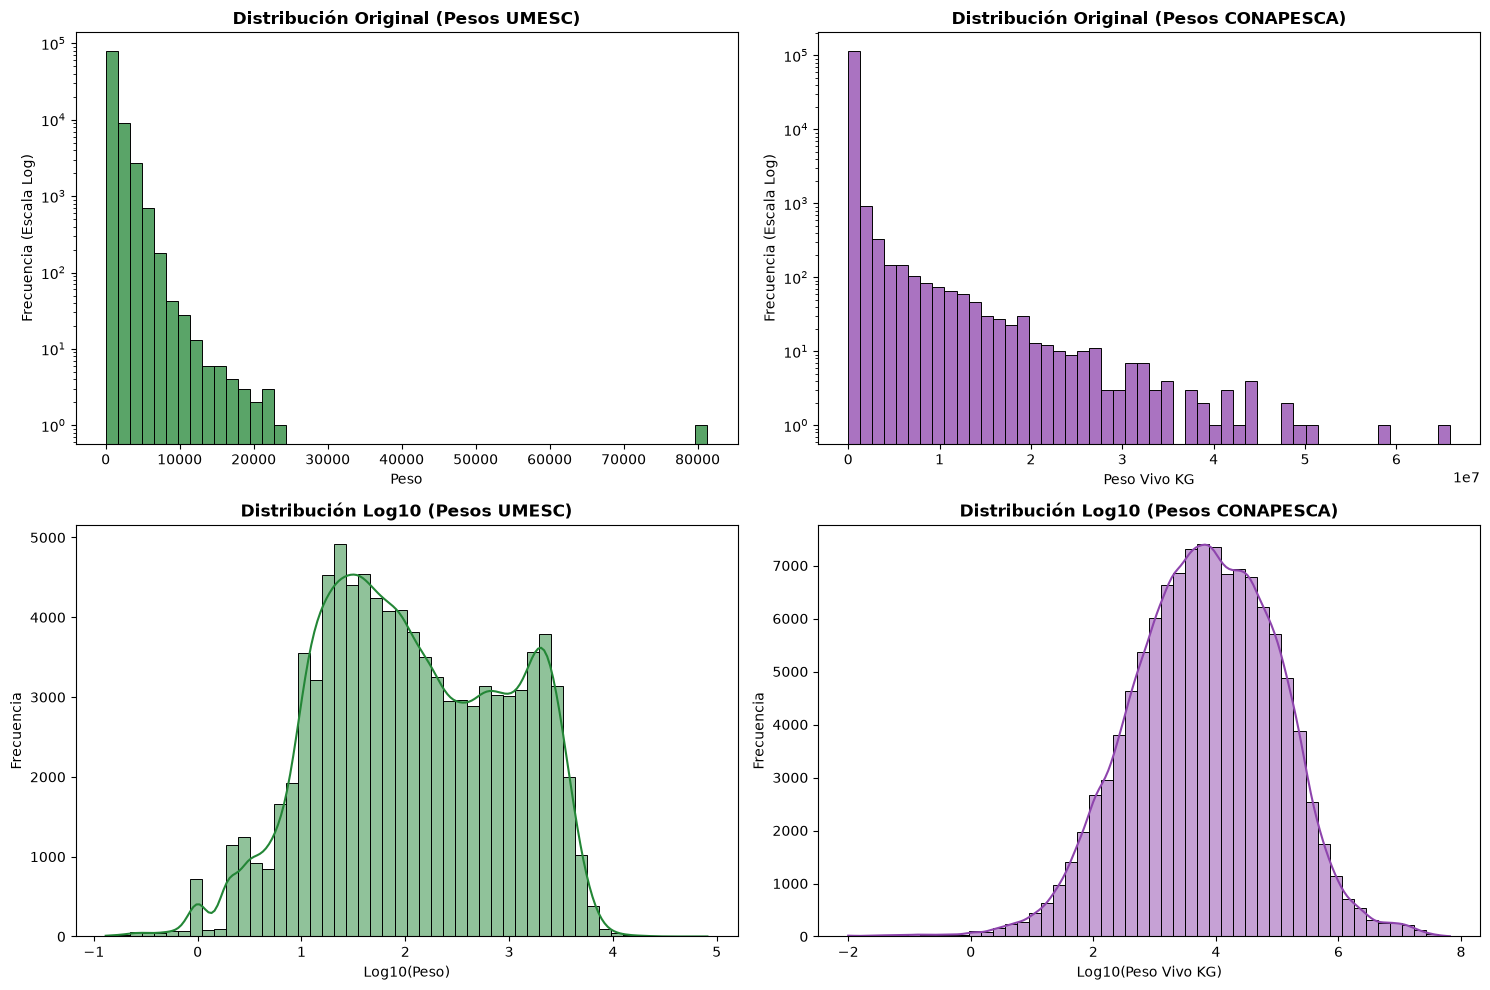

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# ==========================================
# Fila 1: Antes de la transformación (Datos Originales)
# ==========================================
# Histograma Original UMESC (SIN KDE para evitar que se rompa el eje Y logarítmico)
sns.histplot(m1_orig, bins=50, kde=False, ax=axes[0, 0], color='#238636')
axes[0, 0].set_title("Distribución Original (Pesos UMESC)", fontweight='bold')
axes[0, 0].set_xlabel("Peso")
axes[0, 0].set_ylabel("Frecuencia (Escala Log)")
axes[0, 0].set_yscale('log') 

# Histograma Original CONAPESCA (SIN KDE)
sns.histplot(m2_orig, bins=50, kde=False, ax=axes[0, 1], color='#8E44AD')
axes[0, 1].set_title("Distribución Original (Pesos CONAPESCA)", fontweight='bold')
axes[0, 1].set_xlabel("Peso Vivo KG")
axes[0, 1].set_ylabel("Frecuencia (Escala Log)")
axes[0, 1].set_yscale('log') 

# ==========================================
# Fila 2: Después de la transformación (Log10)
# ==========================================
# Histograma Log10 UMESC (CON KDE, aquí sí funciona porque la escala X está comprimida)
sns.histplot(muestra1, bins=50, kde=True, ax=axes[1, 0], color='#238636')
axes[1, 0].set_title("Distribución Log10 (Pesos UMESC)", fontweight='bold')
axes[1, 0].set_xlabel("Log10(Peso)")
axes[1, 0].set_ylabel("Frecuencia")

# Histograma Log10 CONAPESCA (CON KDE)
sns.histplot(muestra2, bins=50, kde=True, ax=axes[1, 1], color='#8E44AD')
axes[1, 1].set_title("Distribución Log10 (Pesos CONAPESCA)", fontweight='bold')
axes[1, 1].set_xlabel("Log10(Peso Vivo KG)")
axes[1, 1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.savefig('grafica_histogramas.png', dpi=300, bbox_inches='tight')
plt.show()

### 3. Prueba F sobre los datos transformados

In [32]:
# Tamaños de muestra y Grados de libertad
n1, n2 = len(muestra1), len(muestra2)
gl1, gl2 = n1 - 1, n2 - 1

# Varianzas de cada muestra (logarítmicas)
var1 = np.var(muestra1, ddof=1)
var2 = np.var(muestra2, ddof=1)

# Asegurar que s1^2 > s2^2 para el numerador
if var1 < var2:
    var1, var2 = var2, var1
    gl1, gl2 = gl2, gl1

F_p = var1 / var2
alpha = 0.05
F_inf = st.f.ppf(alpha / 2, gl1, gl2)
F_sup = st.f.ppf(1 - alpha / 2, gl1, gl2)
p_value = 2 * min(st.f.cdf(F_p, gl1, gl2), 1 - st.f.cdf(F_p, gl1, gl2))

print("--- Resultados de la Prueba F (Escala Logarítmica) ---")
print(f"Varianza Mayor: {var1:.4f}")
print(f"Varianza Menor: {var2:.4f}")
print(f"Estadístico de prueba F_p: {F_p:.4f}")
print(f"Valor crítico inferior (F_inf): {F_inf:.4f}")
print(f"Valor crítico superior (F_sup): {F_sup:.4f}")
print(f"p-value: {p_value:.4e}")

--- Resultados de la Prueba F (Escala Logarítmica) ---
Varianza Mayor: 1.3999
Varianza Menor: 0.8014
Estadístico de prueba F_p: 1.7468
Valor crítico inferior (F_inf): 0.9879
Valor crítico superior (F_sup): 1.0123
p-value: 0.0000e+00


In [33]:
if F_p < F_inf or F_p > F_sup:
    decision = "Rechazar H0"
else:
    decision = "No rechazar H0"

print(f"Decisión: {decision}")
print("Interpretación: A pesar de haber estandarizado las escalas usando logaritmos, la dispersión (varianza logarítmica) de la pesca comercial sigue siendo estadísticamente diferente de los especímenes individuales.")

Decisión: Rechazar H0
Interpretación: A pesar de haber estandarizado las escalas usando logaritmos, la dispersión (varianza logarítmica) de la pesca comercial sigue siendo estadísticamente diferente de los especímenes individuales.


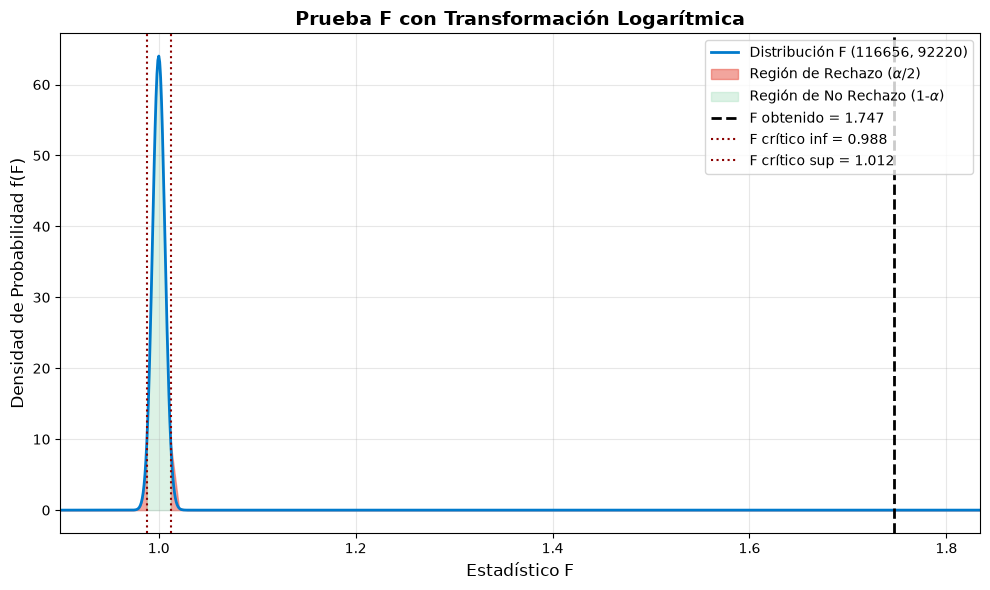

In [34]:
# Gráfica de Distribución F (Ahora sí se verá bien proporcionada)
x_min = min(0.9, F_inf * 0.95)
x_max = max(1.1, F_sup * 1.05, F_p * 1.05)
x = np.linspace(x_min, x_max, 1000)
y = st.f.pdf(x, gl1, gl2)

plt.figure(figsize=(10, 6))
plt.plot(x, y, label=f'Distribución F ({gl1}, {gl2})', color='#007ACC', linewidth=2)

x_rej_inf = np.linspace(x_min, F_inf, 100)
plt.fill_between(x_rej_inf, st.f.pdf(x_rej_inf, gl1, gl2), color='#E74C3C', alpha=0.5, label=r'Región de Rechazo ($\alpha/2$)')

x_rej_sup = np.linspace(F_sup, x_max, 100)
plt.fill_between(x_rej_sup, st.f.pdf(x_rej_sup, gl1, gl2), color='#E74C3C', alpha=0.5)

x_acc = np.linspace(F_inf, F_sup, 500)
plt.fill_between(x_acc, st.f.pdf(x_acc, gl1, gl2), color='#A9DFBF', alpha=0.4, label=r'Región de No Rechazo (1-$\alpha$)')

plt.axvline(F_p, color='black', linestyle='--', linewidth=2, label=f'F obtenido = {F_p:.3f}')
plt.axvline(F_inf, color='darkred', linestyle=':', linewidth=1.5, label=f'F crítico inf = {F_inf:.3f}')
plt.axvline(F_sup, color='darkred', linestyle=':', linewidth=1.5, label=f'F crítico sup = {F_sup:.3f}')

plt.title("Prueba F con Transformación Logarítmica", fontsize=14, fontweight='bold')
plt.xlabel("Estadístico F", fontsize=12)
plt.ylabel("Densidad de Probabilidad f(F)", fontsize=12)
plt.legend(loc='upper right')
plt.grid(alpha=0.3)
plt.xlim(x_min, x_max)
plt.tight_layout()
plt.savefig('grafica_distribucion_f.png', dpi=300, bbox_inches='tight')
plt.show()